# Risk model: evaluation, with the thresholds frozen before the test set is touched

> **Everything here is synthetic.** The fraud patterns were written by the project author (`src/mandate_gate/risk/synth.py`).
> These results show that the *evaluation method* is sound. They say nothing about how any model would perform on real fraud,
> and the scores mean nothing outside the simulator.

What this notebook does, in order:

1. Generate about 1% fraud, time-ordered.
2. Split **by time** into train / validation / test (no shuffling).
3. Fit on **train only**. Choose the two routing thresholds on **validation only**.
4. **Freeze** the thresholds to a file and record its hash.
5. Only then score the **test** split, and report precision, recall and PR-AUC next to a **never-fraud baseline**.
6. Show the top-3 reason codes the gate would log. They are exact: a logistic regression's terms add up to its score.

The advisory score can only make a decision *stricter*; the deterministic rules still decide first.

In [1]:
import hashlib, json, sys, tempfile
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

from mandate_gate.risk import evaluate as ev
from mandate_gate.risk.features import FEATURE_NAMES
from mandate_gate.risk.model import fit_model
from mandate_gate.risk.synth import generate
from mandate_gate.risk.thresholds import choose_thresholds

SEED, N_AGENTS, DAYS = 7, 300, 90          # the same settings as `mandate-gate evaluate-risk`
DENY_PRECISION, REVIEW_RECALL = 0.95, 0.90  # targets for the two thresholds

## 1. Data

Fraud is about 1% of transactions. Some legitimate purchases look suspicious (large, late at night, new merchant) and some fraud looks routine, so the classes overlap on purpose.

In [2]:
df = generate(n_agents=N_AGENTS, days=DAYS, seed=SEED)
print(f"{len(df):,} transactions, {df.is_fraud.sum()} fraud ({df.is_fraud.mean():.2%})\n")
print(df.groupby("pattern").agg(rows=("is_fraud", "size"), fraud=("is_fraud", "sum")).to_string())

48,154 transactions, 495 fraud (1.03%)

                rows  fraud
pattern                    
cap_hugging      148    148
card_testing     160    160
drain            163    163
legit          47359      0
legit_unusual    300      0
slow_novel        24     24


## 2. Time-ordered split, and a leakage check

A random split would let the model train on the future and be tested on the past, and would put one fraud burst on both sides of the line.
The split below is by time. The assertions are the leakage checks: the splits do not overlap in time, and each history feature at time *t* can be
recomputed from rows strictly before *t* (so no future information is inside a feature).

In [3]:
train, val, test = ev.time_split(df)
assert train.ts.max() < val.ts.min() and val.ts.max() < test.ts.min(), "splits overlap in time"
assert len(train) + len(val) + len(test) == len(df)

def point_in_time_ok(frame, n_agents=40):
    # recompute three history features from earlier rows only, for a sample of agents
    for agent in frame.agent_id.unique()[:n_agents]:
        rows = frame[frame.agent_id == agent].sort_values("ts", kind="mergesort")
        past, merchants = [], set()
        for _, r in rows.iterrows():
            assert r.txns_last_hour == sum(1 for t in past if t > r.ts - 3600)
            assert r.new_merchant == (0.0 if r.merchant in merchants else 1.0)
            past.append(r.ts); merchants.add(r.merchant)
    return True

print("history features use only earlier events:", point_in_time_ok(df))
summary = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "fraud": [int(train.is_fraud.sum()), int(val.is_fraud.sum()), int(test.is_fraud.sum())],
    "fraud rate": [f"{p.is_fraud.mean():.2%}" for p in (train, val, test)],
    "from (UTC)": [pd.to_datetime(p.ts.min(), unit="s").strftime("%Y-%m-%d") for p in (train, val, test)],
    "to (UTC)": [pd.to_datetime(p.ts.max(), unit="s").strftime("%Y-%m-%d") for p in (train, val, test)],
}, index=["train", "validation", "test"])
print(summary.to_string())
print("\nNote: the `slow_novel` fraud pattern only exists in the last 20% of the timeline, so the test split contains a pattern the model never saw.")

history features use only earlier events: True
             rows  fraud fraud rate  from (UTC)    to (UTC)
train       28892    270      0.93%  2025-10-09  2025-11-30
validation   9631     92      0.96%  2025-11-30  2025-12-17
test         9631    133      1.38%  2025-12-17  2026-01-06

Note: the `slow_novel` fraud pattern only exists in the last 20% of the timeline, so the test split contains a pattern the model never saw.


## 3. Fit on train only

In [4]:
X = list(FEATURE_NAMES)
model = fit_model(train[X].to_numpy(), train.is_fraud.to_numpy(), seed=SEED)
print("model: logistic regression |", len(model.coef), "input columns | reason codes:", model.explanation_method)
print("saved-model arithmetic vs scikit-learn, max |probability difference|:", f"{model.fit_parity_max_abs_diff:.1e}")

model: logistic regression | 17 input columns | reason codes: linear
saved-model arithmetic vs scikit-learn, max |probability difference|: 9.4e-16


## 4. Choose thresholds on validation, then freeze them

* **deny** at the lowest score where validation precision is still at least 0.95 (auto-deny only when the model is sure);
* **review** at the highest score where validation recall is still at least 0.90 (everything from here up goes to a human).

Below the review threshold a proposal may be approved, but only if every rule check already passed.

In [5]:
s_val = model.predict(val[X].to_numpy())
y_val = val.is_fraud.to_numpy()
thr = choose_thresholds(y_val, s_val, DENY_PRECISION, REVIEW_RECALL)

freeze_dir = Path(tempfile.mkdtemp())
frozen_path = freeze_dir / "thresholds_frozen.json"
frozen_path.write_text(json.dumps(thr, sort_keys=True, indent=2))
frozen_sha = hashlib.sha256(frozen_path.read_bytes()).hexdigest()
print("thresholds chosen on VALIDATION only:", thr)
print("frozen file sha256:", frozen_sha[:16], "...")
c = ev.confusion(y_val.tolist(), s_val.tolist(), thr["risk_review_threshold"])
print("\nvalidation, at the review threshold:", c, "-> recall", round(ev.precision_recall(c)[1], 3))

thresholds chosen on VALIDATION only: {'risk_review_threshold': 0.03479873285718275, 'risk_deny_threshold': 0.6876644108892366}
frozen file sha256: 3916de443a62bbaa ...

validation, at the review threshold: {'tp': 83, 'fp': 83, 'fn': 9, 'tn': 9456} -> recall 0.902


## 5. Now, and only now, the test split

The thresholds are reloaded from the frozen file. Nothing below this line is allowed to change them.

In [6]:
frozen = json.loads(frozen_path.read_text())
t_review, t_deny = frozen["risk_review_threshold"], frozen["risk_deny_threshold"]

y_test = test.is_fraud.to_numpy()
s_test = model.predict(test[X].to_numpy())
prevalence = y_test.mean()
pr_auc = average_precision_score(y_test, s_test)

c_review = ev.confusion(y_test.tolist(), s_test.tolist(), t_review)
c_deny = ev.confusion(y_test.tolist(), s_test.tolist(), t_deny)
p_r, r_r = ev.precision_recall(c_review)
p_d, r_d = ev.precision_recall(c_deny)

# A deliberately simple rule baseline: "flag anything at 85% or more of the per-transaction cap".
rule_flag = (test.amt_frac_txn_cap >= 0.85).to_numpy()
rule_tp = int((rule_flag & (y_test == 1)).sum()); rule_fp = int((rule_flag & (y_test == 0)).sum())

table = pd.DataFrame([
    ["Never-fraud baseline (predict 'legitimate' always)", prevalence, None, 0.0, 1 - prevalence],
    ["One simple rule: amount >= 85% of cap", None, rule_tp / max(rule_tp + rule_fp, 1), rule_tp / y_test.sum(), None],
    ["Model, flagged at the review threshold", pr_auc, p_r, r_r, (c_review["tp"] + c_review["tn"]) / len(y_test)],
    ["Model, flagged at the deny threshold", pr_auc, p_d, r_d, (c_deny["tp"] + c_deny["tn"]) / len(y_test)],
], columns=["", "PR-AUC", "precision", "recall", "accuracy"])
print(f"test split: {len(y_test):,} transactions, {int(y_test.sum())} fraud ({prevalence:.2%})\n")
print(table.to_string(index=False, float_format=lambda v: f"{v:.3f}", na_rep="n/a"))
print(f"\nconfusion at review threshold {t_review:.4f}: {c_review}")
print(f"confusion at deny threshold   {t_deny:.4f}: {c_deny}")
assert hashlib.sha256(frozen_path.read_bytes()).hexdigest() == frozen_sha, "thresholds changed after the test split was scored"
print("\nfrozen thresholds file unchanged since before the test split was scored: OK")

test split: 9,631 transactions, 133 fraud (1.38%)

                                                    PR-AUC  precision  recall  accuracy
Never-fraud baseline (predict 'legitimate' always)   0.014        n/a   0.000     0.986
             One simple rule: amount >= 85% of cap     n/a      0.184   0.211       n/a
            Model, flagged at the review threshold   0.777      0.602   0.752     0.990
              Model, flagged at the deny threshold   0.777      0.970   0.481     0.993

confusion at review threshold 0.0348: {'tp': 100, 'fp': 66, 'fn': 33, 'tn': 9432}
confusion at deny threshold   0.6877: {'tp': 64, 'fp': 2, 'fn': 69, 'tn': 9496}

frozen thresholds file unchanged since before the test split was scored: OK


**Why accuracy is not the headline.** The never-fraud baseline is ~98.6% accurate and catches nothing. At this fraud rate accuracy cannot tell a useful model from a useless one;
precision, recall, PR-AUC and the cost of each kind of error can. A constant score has PR-AUC equal to the fraud rate (the dotted line in the next plot).

In [7]:
# Hand-check: recompute precision and recall from the confusion matrix, and against scikit-learn.
tp, fp, fn, tn = (c_review[k] for k in ("tp", "fp", "fn", "tn"))
by_hand_precision, by_hand_recall = tp / (tp + fp), tp / (tp + fn)
from sklearn.metrics import precision_score, recall_score
flagged = s_test >= t_review
assert abs(by_hand_precision - precision_score(y_test, flagged)) < 1e-12
assert abs(by_hand_recall - recall_score(y_test, flagged)) < 1e-12
print(f"by hand: precision = {tp}/({tp}+{fp}) = {by_hand_precision:.4f}, recall = {tp}/({tp}+{fn}) = {by_hand_recall:.4f}  (matches scikit-learn)")

by hand: precision = 100/(100+66) = 0.6024, recall = 100/(100+33) = 0.7519  (matches scikit-learn)


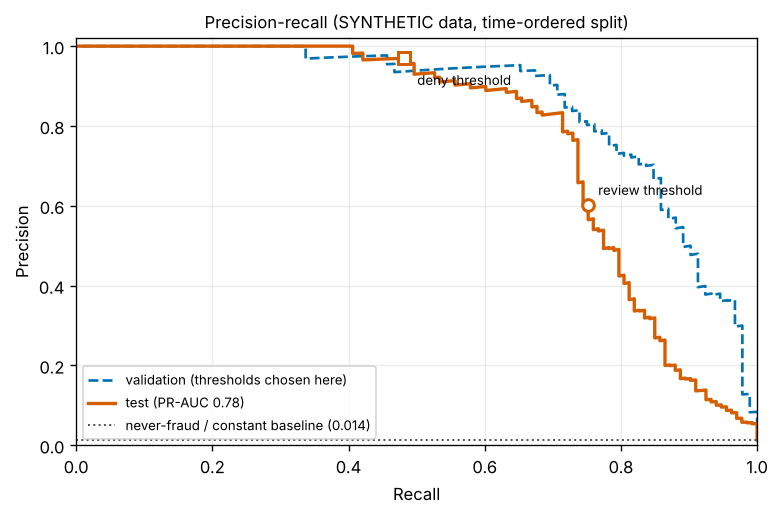

In [8]:
pv, rv, _ = precision_recall_curve(y_val, s_val)
pt, rt, _ = precision_recall_curve(y_test, s_test)
fig, ax = plt.subplots(figsize=(6.6, 4.4), dpi=120)
ax.plot(rv, pv, ls="--", lw=1.6, color="#0072B2", label="validation (thresholds chosen here)")
ax.plot(rt, pt, lw=2.0, color="#D55E00", label=f"test (PR-AUC {pr_auc:.2f})")
ax.axhline(prevalence, ls=":", lw=1.2, color="#555555", label=f"never-fraud / constant baseline ({prevalence:.3f})")
for name, (p, r), marker in (("review", (p_r, r_r), "o"), ("deny", (p_d, r_d), "s")):
    ax.plot([r], [p], marker, color="#D55E00", ms=7, mfc="white", mew=1.8)
    ax.annotate(f"{name} threshold", (r, p), textcoords="offset points", xytext=(8, -16) if name == "deny" else (6, 6), fontsize=8)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall (SYNTHETIC data, time-ordered split)", fontsize=10)
ax.grid(alpha=0.25); ax.legend(fontsize=8, loc="lower left"); fig.tight_layout()
plt.show()

## 6. Where proposals land, and where the model is weak

In [9]:
route = np.where(s_test >= t_deny, "deny", np.where(s_test >= t_review, "review", "approve"))
routing = pd.crosstab(pd.Categorical(route, ["approve", "review", "deny"]), np.where(y_test == 1, "fraud", "legitimate"))
print(routing.to_string(), "\n")

fraud = test[test.is_fraud == 1].copy()
fraud["caught"] = s_test[fraud.index.map(test.index.get_loc)] >= t_review
print(fraud.groupby("pattern").caught.agg(n="size", caught="sum", recall="mean").round(3).to_string())
print("\n`slow_novel` was never seen in training: the model mostly misses it. A real system would need drift monitoring and fresh labels.")

col_0    fraud  legitimate
row_0                     
approve     33        9432
review      36          64
deny        64           2 

               n  caught  recall
pattern                         
cap_hugging   28      23   0.821
card_testing  40      37   0.925
drain         41      39   0.951
slow_novel    24       1   0.042

`slow_novel` was never seen in training: the model mostly misses it. A real system would need drift monitoring and fresh labels.


## 7. Reason codes

The gate stores the top-3 reasons next to every score. For a logistic regression they need no approximation: each feature's term is `weight * (value - training mean) / scale`, and the terms plus the intercept add up to the log-odds exactly.
The check below confirms that on real rows. (An earlier version of this project used gradient boosting with a hand-written TreeSHAP; it scored about the same on this data and was cut. See DECISIONS.md.)

In [10]:
flagged_idx = np.flatnonzero(s_test >= t_deny)[:3]
for i in flagged_idx:
    x = [float(test.iloc[i][n]) for n in X]
    contrib = model.contributions(x)
    gap = abs(contrib.sum() + model.intercept - float(model.logit(np.asarray([x]))[0]))
    print(f"[{test.iloc[i].pattern}] score {s_test[i]:.3f}  (additivity gap {gap:.1e})")
    for r in model.explain(x):
        print("    ", r)

[legit_unusual] score 0.749  (additivity gap 1.8e-15)
     CATEGORY(electronics):+5.35
     AMOUNT_VS_TXN_CAP(0.932):+4.81
     NEW_MERCHANT(1):+3.47
[drain] score 0.833  (additivity gap 1.8e-15)
     CATEGORY(electronics):+5.35
     NEW_MERCHANT(1):+3.47
     AMOUNT_VS_TXN_CAP(0.62):+2.82
[cap_hugging] score 1.000  (additivity gap 0.0e+00)
     CATEGORY(gift_cards):+18.13
     AMOUNT_VS_TXN_CAP(0.902):+4.62
     NEW_MERCHANT(1):+3.47


## 8. This notebook reproduces the shipped model

The committed `artifacts/risk/` is what the demo and the gate use. These cells fail if it ever drifts from what is computed here.

In [11]:
shipped = json.loads((ROOT / "artifacts" / "risk" / "thresholds.json").read_text())
shipped_metrics = json.loads((ROOT / "artifacts" / "risk" / "metrics.json").read_text())
assert abs(shipped["risk_review_threshold"] - t_review) < 1e-12 and abs(shipped["risk_deny_threshold"] - t_deny) < 1e-12
assert shipped_metrics["model"]["at_review_threshold"]["tp"] == c_review["tp"]
assert abs(shipped_metrics["model"]["pr_auc"] - round(pr_auc, 4)) < 1e-9
print("thresholds, confusion matrix and PR-AUC match artifacts/risk: OK")

thresholds, confusion matrix and PR-AUC match artifacts/risk: OK


## Limits (also in the README)

* Synthetic data: the metrics validate the method, not real-world performance.
* The test fraud rate (1.4%) is higher than train/validation (0.9%) because of the late-appearing pattern, by design.
* Thresholds were tuned on one validation window; there is no drift monitoring and no delayed-label handling.
* **Shortcut learning.** In this simulator legitimate agents never buy gift cards and most fraud does, so the model leans hard on category
  (the reason codes above show `CATEGORY(...)` contributing a large positive term for categories that are rare in legitimate traffic, such as gift cards and electronics). That is a property of my generator, not of real fraud.
  The reason codes are what exposed it, which is part of why they are logged.
* The model is linear on purpose. It cannot learn interactions (for example "large AND new merchant AND night"); on this data that costs about 0.03 PR-AUC against gradient boosting, and the data is too simple to say more.
* The risk score is advisory. It can send a proposal to a human or deny it; it can never approve one the rules denied.